# Mekanisme Perhitungan Konsistensi Anotasi (*Intra-Annotator Agreement*)
### Tugas Akhir / Skripsi: *Generative Aspect-Based Sentiment Analysis* (GABSA) Ulasan Layanan Rumah Sakit

---

## 📌 Latar Belakang & Tujuan Metodologis

Penyusunan dataset acuan (*ground truth*) merupakan fondasi penting dalam pelatihan dan evaluasi model kecerdasan buatan, khususnya model generatif (*Large Language Model*). Pada penelitian ini, pelabelan ulasan pasien rumah sakit dari Google Maps dilakukan oleh **satu orang anotator utama** dengan panduan anotasi berbasis dimensi kualitas pelayanan kesehatan (**SERVQUAL**).

Karena seluruh data diberi label oleh satu anotator, mutu data diuji melalui evaluasi **stabilitas keputusan anotasi dari waktu ke waktu** yang dikenal sebagai:
$$\textbf{Intra-Annotator Agreement} \quad \text{atau} \quad \textbf{Test-Retest Reliability}$$

### 🔍 Parameter Pengujian:
1. **Populasi Data Awal (Sesi 1):** $7.927$ baris ulasan dari file `dataset/absa_labeled_data_combined_balanced.jsonl`.
2. **Sampel Anotasi Ulang (Sesi 2):** $n = 800$ ulasan acak ($10{,}09\%$ dari total pool) dari file `dataset/absa_reannotated_data.jsonl`.
3. **Jeda Waktu (*Time Lag*):** $4$ minggu antara sesi pertama dan sesi kedua untuk meminimalkan efek memori/ingatan jangka pendek anotator.
4. **Karakteristik Data:** *Multi-label* dan *multi-aspect* (satu ulasan dapat memuat beberapa aspek dan beberapa polaritas sentimen sekaligus).
5. **Penanganan Evidence Span:** Batas *evidence span* (`start`, `end`) adalah substring teks kontinu dan diuji terpisah melalui *expert spot-checking*. Untuk pengujian konsistensi matematis, pengujian dilakukan pada tingkat **himpunan label (*set-label*)**.

---

## 📐 Empat Metrik Konsistensi yang Digunakan
Sesuai rancangan metodologi pada **Subbab 2.7** dan hasil pada **Subbab 3.2 (Tabel 3.2)**, konsistensi diukur menggunakan **empat metrik komplementer**:
1. **Kesepakatan Set-Label ($P_o$):** Mengukur proporsi ulasan yang himpunan labelnya cocok eksak $100\%$ (paling ketat, tanpa koreksi kebetulan).
2. **Koefisien Mean Jaccard ($\bar{J}$):** Mengukur rata-rata irisan per gabungan himpunan label per ulasan (menghargai kesamaan parsial).
3. **Cohen's Kappa ($\kappa$) per Kategori:** Menerapkan formulasi *chance-corrected* klasik pada matriks kontingensi $2 \times 2$ biner untuk setiap kategori, lalu dirata-ratakan.
4. **Krippendorff's Alpha ($\alpha$):** Mengukur reliabilitas himpunan label multi-label dengan jarak Jaccard dan distribusi kebetulan gabungan seluruh ulasan.


---
## 1. Setup Lingkungan & Definisi Taksonomi Anotasi

Pada tahap ini, kita mengimpor pustaka standar Python (`json`, `collections`, `random`, `math`, `pathlib`). Kode dirancang tanpa dependensi eksternal berat agar portabel dan dapat dijalankan di berbagai lingkungan (Jupyter Notebook lokal, VS Code, maupun Google Colab).

Taksonomi yang digunakan terdiri atas:
- **7 Kategori Aspek:** `administrasi`, `fasilitas`, `kebersihan`, `parkir_akses`, `pelayanan`, `tenaga_medis`, `waktu_tunggu`
- **3 Kelas Sentimen:** `negatif`, `netral`, `positif`
- **21 Kombinasi Pasangan Aspek–Sentimen:** $7 \times 3 = 21$ kemungkinan pasangan.


In [1]:
import json
import os
import random
from collections import Counter
from pathlib import Path

# Resolusi path file dataset (fleksibel jika dijalankan dari dalam direktori 'notebook/' atau root direktori)
def resolve_path(rel_path):
    p = Path(rel_path)
    if p.exists():
        return str(p)
    p_parent = Path("..") / rel_path
    if p_parent.exists():
        return str(p_parent)
    return rel_path

PATH_SESI_1 = resolve_path("dataset/absa_labeled_data_combined_balanced.jsonl")
PATH_SESI_2 = resolve_path("dataset/absa_reannotated_data.jsonl")

# Definisi taksonomi penelitian
ASPECTS = [
    'administrasi',
    'fasilitas',
    'kebersihan',
    'parkir_akses',
    'pelayanan',
    'tenaga_medis',
    'waktu_tunggu'
]

SENTS = ['negatif', 'netral', 'positif']

PAIRS = [f"{a}__{s}" for a in ASPECTS for s in SENTS]

# Metadata 3 dimensi evaluasi
DIMENSIONS = [
    ("Kategori Aspek", ASPECTS, lambda c: c.split('__')[0]),
    ("Kelas Sentimen", SENTS, lambda c: c.split('__')[1]),
    ("Pasangan Aspek-Sentimen", PAIRS, lambda c: c),
]

print("=" * 70)
print("KONFIGURASI SISTEM DAN TAKSONOMI")
print("=" * 70)
print(f"Path Anotasi Sesi 1 (Acuan Awal) : {PATH_SESI_1}")
print(f"Path Anotasi Sesi 2 (Re-anotasi) : {PATH_SESI_2}")
print(f"Jumlah Kategori Aspek            : {len(ASPECTS)} kategori -> {ASPECTS}")
print(f"Jumlah Kelas Sentimen            : {len(SENTS)} kelas    -> {SENTS}")
print(f"Jumlah Pasangan Aspek-Sentimen   : {len(PAIRS)} kombinasi")
print("=" * 70)


KONFIGURASI SISTEM DAN TAKSONOMI
Path Anotasi Sesi 1 (Acuan Awal) : dataset/absa_labeled_data_combined_balanced.jsonl
Path Anotasi Sesi 2 (Re-anotasi) : dataset/absa_reannotated_data.jsonl
Jumlah Kategori Aspek            : 7 kategori -> ['administrasi', 'fasilitas', 'kebersihan', 'parkir_akses', 'pelayanan', 'tenaga_medis', 'waktu_tunggu']
Jumlah Kelas Sentimen            : 3 kelas    -> ['negatif', 'netral', 'positif']
Jumlah Pasangan Aspek-Sentimen   : 21 kombinasi


---
## 2. Pemuatan Data dan Penyelarasan Sampel (*ID-Based 1-to-1 Matching*)

Pada data anotasi, setiap ulasan memiliki pengenal unik (`id`).
- Sesi 1 (`absa_labeled_data_combined_balanced.jsonl`) berisi seluruh kumpulan data anotasi acuan ($7.927$ baris).
- Sesi 2 (`absa_reannotated_data.jsonl`) berisi $800$ ulasan yang dianotasi ulang setelah jeda $4$ minggu.

Untuk menghitung konsistensi intra-anotator secara valid:
1. Kita memuat kedua berkas ke dalam kamus berbasis `id`.
2. Kita menyaring baris ulasan sehingga diperoleh pasangan ulasan dengan `id` yang persis sama.
3. Kita memverifikasi bahwa $n = 800$ sampel cocok satu-ke-satu tanpa ambiguitas.


In [2]:
def load_jsonl(filepath):
    data_dict = {}
    line_count = 0
    with open(filepath, 'r', encoding='utf-8') as f:
        for line in f:
            line = line.strip()
            if not line:
                continue
            line_count += 1
            record = json.loads(line)
            data_dict[record['id']] = record
    return data_dict, line_count

# Muat data Sesi 1 dan Sesi 2
data_sesi_1, total_baris_sesi_1 = load_jsonl(PATH_SESI_1)
data_sesi_2, total_baris_sesi_2 = load_jsonl(PATH_SESI_2)

# Ambil ID ulasan yang ada di Sesi 2 dan cocokkan dengan Sesi 1
sample_ids = [uid for uid in data_sesi_2.keys() if uid in data_sesi_1]

# Hitung variabel-variabel ukuran sampel
N_POPULASI = total_baris_sesi_1
N_SAMPEL = len(sample_ids)
PROPORSI_SAMPEL = (N_SAMPEL / N_POPULASI) * 100

print("=" * 70)
print("STATISTIK PEMUATAN DATA & PENYELARASAN SAMPEL")
print("=" * 70)
print(f"Variabel Total Baris Sesi 1 (N_populasi)  : {N_POPULASI} baris")
print(f"Variabel ID Unik Sesi 1                  : {len(data_sesi_1)} ulasan")
print(f"Variabel Total Baris Sesi 2 (Re-anotasi) : {total_baris_sesi_2} baris")
print(f"Variabel Jumlah Sampel Selaras (n)       : {N_SAMPEL} ulasan")
print(f"Variabel Proporsi Sampel Re-anotasi      : {PROPORSI_SAMPEL:.2f}%")
print("=" * 70)

# Tampilkan contoh struktur 1 record ulasan yang selaras
contoh_id = sample_ids[0]
cu_text = data_sesi_2[contoh_id]['text'][:90]
print(f"CONTOH DATASET SELARAS (ID = {contoh_id}):")
print(f"  Teks ulasan : '{cu_text}...'")
print(f"  Label Sesi 1: {data_sesi_1[contoh_id]['label']}")
print(f"  Label Sesi 2: {data_sesi_2[contoh_id]['label']}")
print("=" * 70)


STATISTIK PEMUATAN DATA & PENYELARASAN SAMPEL
Variabel Total Baris Sesi 1 (N_populasi)  : 7927 baris
Variabel ID Unik Sesi 1                  : 6765 ulasan
Variabel Total Baris Sesi 2 (Re-anotasi) : 800 baris
Variabel Jumlah Sampel Selaras (n)       : 800 ulasan
Variabel Proporsi Sampel Re-anotasi      : 10.09%
CONTOH DATASET SELARAS (ID = 1556):
  Teks ulasan : 'Terimakasih rs bhayangkara, saya di rawat di rs di ruang aster, pelayanannya bagus, bersih...'
  Label Sesi 1: [[64, 82, 'pelayanan__positif'], [84, 90, 'kebersihan__positif'], [92, 123, 'fasilitas__positif']]
  Label Sesi 2: [[64, 82, 'pelayanan__positif'], [84, 90, 'kebersihan__positif'], [92, 123, 'fasilitas__positif']]


---
## 3. Ekstraksi Himpunan Label (*Set-Label Representation*) & Proyeksi 3 Dimensi

### 💡 Konsep Operasional Himpunan (*Set*) pada Data Multi-Label
Setiap anotasi mentah memiliki bentuk triplet:
$$\text{label} = [[\text{start}, \text{end}, \text{kode}], \dots], \quad \text{dengan } \text{kode} = \text{aspek}\text{\_\_}\text{sentimen}$$

Sesuai metodologi pada naskah (Subbab 2.7 butir 5):
1. **Posisi span (`start`, `end`) diabaikan** dalam perhitungan indeks konsistensi matematis, karena batas teks adalah substring kontinu yang diperiksa tersendiri lewat validasi pakar.
2. **Duplikasi kategori dikolaps:** jika satu ulasan memiliki dua bukti kalimat untuk aspek `pelayanan`, representasi himpunan otomatis mencatatnya satu kali (`{'pelayanan'}`).

### 📊 Tiga Dimensi Pengukuran
Dari triplet yang sama, kita memproyeksikan ke dalam 3 dimensi evaluasi:
1. **Dimensi Kategori Aspek ($K = 7$):** Mengambil bagian nama aspek sebelum `__` (contoh: `pelayanan`).
2. **Dimensi Kelas Sentimen ($K = 3$):** Mengambil bagian polaritas sentimen setelah `__` (contoh: `positif`). *Catatan: Dimensi ini mengukur polaritas apa saja yang muncul pada ulasan secara agregat.*
3. **Dimensi Pasangan Aspek–Sentimen ($K = 21$):** Mengambil kode lengkap `aspek__sentimen` (contoh: `pelayanan__positif`).

### ⚡ Optimalisasi Bitmask Integer
Untuk efisiensi komputasi, setiap himpunan direpresentasikan sebagai bilangan bulat *bitmask*:
- Bit ke-$j$ bernilai $1$ jika kategori ke-$j$ hadir.
- Operasi gabungan: $A \cup B \Longleftrightarrow a \mid b$
- Operasi irisan: $A \cap B \Longleftrightarrow a \,\&\, b$
- Kardinalitas $|A| \Longleftrightarrow \text{popcount}(a)$
Secara matematis, bitmask **identik 100%** dengan struktur data `set` Python.


In [3]:
def popcount(x):
    """Menghitung jumlah bit bernilai 1 (kardinalitas himpunan)."""
    return bin(x).count('1')

def extract_label_set(record, keyfn):
    """Ekstraksi himpunan label unik dari triplet ulasan."""
    labels = set()
    for item in record.get('label', []):
        code = item[2]
        labels.add(keyfn(code))
    return labels

def masks_of(dataset, row_ids, keyfn, index_map):
    """Mengubah himpunan label seluruh ulasan menjadi list integer bitmask."""
    masks = []
    for uid in row_ids:
        m = 0
        for item in dataset[uid].get('label', []):
            code = item[2]
            idx = index_map[keyfn(code)]
            m |= (1 << idx)  # Operasi OR bitwise mengkolaps duplikasi secara otomatis
        masks.append(m)
    return masks

# Demonstrasi pada ulasan nyata: ulasan ID = 15 dan ID = 27
print("=" * 70)
print("CONTOH REKAYASA HIMPUNAN LABEL PADA ULASAN NYATA")
print("=" * 70)

for cid in [15, 27]:
    if cid in sample_ids:
        u_sesi1 = data_sesi_1[cid]
        u_sesi2 = data_sesi_2[cid]
        u_text = u_sesi1['text']
        print(f"Kasus Ulasan ID: {cid}")
        print(f"  Teks : '{u_text}'")
        for dim_name, _, kfn in DIMENSIONS:
            set_a = extract_label_set(u_sesi1, kfn)
            set_b = extract_label_set(u_sesi2, kfn)
            irisan = set_a & set_b
            gabungan = set_a | set_b
            jaccard_ex = len(irisan) / len(gabungan) if len(gabungan) > 0 else 1.0
            print(f"  [{dim_name}]")
            print(f"    Sesi 1 (A) : {set_a}")
            print(f"    Sesi 2 (B) : {set_b}")
            print(f"    A == B     : {set_a == set_b} (Indikator P_o = {1 if set_a == set_b else 0})")
            print(f"    Irisan     : {irisan} (|A ∩ B| = {len(irisan)})")
            print(f"    Gabungan   : {gabungan} (|A ∪ B| = {len(gabungan)})")
            print(f"    Jaccard    : {jaccard_ex:.4f} (Jarak delta = {1.0 - jaccard_ex:.4f})")
        print("-" * 70)


CONTOH REKAYASA HIMPUNAN LABEL PADA ULASAN NYATA
Kasus Ulasan ID: 15
  Teks : 'Dari awal sampai selesai, pengalaman di sini selalu menyenangkan dan profesional.'
  [Kategori Aspek]
    Sesi 1 (A) : {'pelayanan'}
    Sesi 2 (B) : {'pelayanan', 'fasilitas'}
    A == B     : False (Indikator P_o = 0)
    Irisan     : {'pelayanan'} (|A ∩ B| = 1)
    Gabungan   : {'pelayanan', 'fasilitas'} (|A ∪ B| = 2)
    Jaccard    : 0.5000 (Jarak delta = 0.5000)
  [Kelas Sentimen]
    Sesi 1 (A) : {'positif'}
    Sesi 2 (B) : {'positif'}
    A == B     : True (Indikator P_o = 1)
    Irisan     : {'positif'} (|A ∩ B| = 1)
    Gabungan   : {'positif'} (|A ∪ B| = 1)
    Jaccard    : 1.0000 (Jarak delta = 0.0000)
  [Pasangan Aspek-Sentimen]
    Sesi 1 (A) : {'pelayanan__positif'}
    Sesi 2 (B) : {'pelayanan__positif', 'fasilitas__positif'}
    A == B     : False (Indikator P_o = 0)
    Irisan     : {'pelayanan__positif'} (|A ∩ B| = 1)
    Gabungan   : {'pelayanan__positif', 'fasilitas__positif'} (|A ∪ B| =

---
## 4. Metrik 1: Kesepakatan Set-Label ($P_o$ / Exact Match)

### 📐 Rumus Matematis (Persamaan pada Subbab 2.7)
$$P_o^{(d)} = \frac{1}{n}\sum_{i=1}^{n} \mathbb{1}\!\left[ A_i^{(d)} = B_i^{(d)} \right]$$

di mana:
- $n = 800$ adalah total ulasan yang dianotasi ulang.
- $A_i^{(d)}$ adalah himpunan label ulasan ke-$i$ pada Sesi 1 untuk dimensi $d$.
- $B_i^{(d)}$ adalah himpunan label ulasan ke-$i$ pada Sesi 2 untuk dimensi $d$.
- $\mathbb{1}[\cdot]$ adalah fungsi indikator biner:
  $$\mathbb{1}\!\left[ A_i^{(d)} = B_i^{(d)} \right] = \begin{cases} 1, & \text{jika } A_i^{(d)} = B_i^{(d)} \\ 0, & \text{jika } A_i^{(d)} \neq B_i^{(d)} \end{cases}$$

Oleh karena itu, perhitungan praktisnya adalah:
$$P_o^{(d)} = \frac{\text{Jumlah Ulasan Cocok Eksak}}{n} = \frac{\text{Cocok Eksak}}{800}$$

### 🔍 Karakteristik Metrik:
- **Sangat Ketat (*Strict*):** Satu label saja yang bertambah atau berkurang akan membuat ulasan bernilai $0$, meskipun ada 2 label lain yang sama.
- **Tanpa Koreksi Peluang Keceplosan/Kebetulan:** Nilai kesepakatan murni mencerminkan kesamaan himpunan secara utuh.


In [4]:
hasil_po = {}

print("=" * 70)
print("PERHITUNGAN METRIK 1: KESEPAKATAN SET-LABEL (P_o)")
print("=" * 70)

for dim_name, keys, keyfn in DIMENSIONS:
    index_map = {k: i for i, k in enumerate(keys)}
    S1 = masks_of(data_sesi_1, sample_ids, keyfn, index_map)
    S2 = masks_of(data_sesi_2, sample_ids, keyfn, index_map)
    
    n = len(sample_ids)
    cocok_eksak = sum(1 for a, b in zip(S1, S2) if a == b)
    tidak_cocok = n - cocok_eksak
    po_desimal = cocok_eksak / n
    po_persen = po_desimal * 100.0
    hasil_po[dim_name] = po_desimal
    
    print(f"### Dimensi: {dim_name}")
    print(f"  Variabel n (Total Ulasan)          : {n}")
    print(f"  Variabel Cocok Eksak (A_i == B_i)  : {cocok_eksak}")
    print(f"  Variabel Tidak Cocok (A_i != B_i)  : {tidak_cocok}")
    print(f"  Rumus P_o = {cocok_eksak} / {n}")
    print(f"  Nilai P_o (Desimal)                : {po_desimal:.6f}")
    print(f"  Nilai P_o (Persentase)             : {po_persen:.2f}%")
    print("-" * 70)


PERHITUNGAN METRIK 1: KESEPAKATAN SET-LABEL (P_o)
### Dimensi: Kategori Aspek
  Variabel n (Total Ulasan)          : 800
  Variabel Cocok Eksak (A_i == B_i)  : 730
  Variabel Tidak Cocok (A_i != B_i)  : 70
  Rumus P_o = 730 / 800
  Nilai P_o (Desimal)                : 0.912500
  Nilai P_o (Persentase)             : 91.25%
----------------------------------------------------------------------
### Dimensi: Kelas Sentimen
  Variabel n (Total Ulasan)          : 800
  Variabel Cocok Eksak (A_i == B_i)  : 758
  Variabel Tidak Cocok (A_i != B_i)  : 42
  Rumus P_o = 758 / 800
  Nilai P_o (Desimal)                : 0.947500
  Nilai P_o (Persentase)             : 94.75%
----------------------------------------------------------------------
### Dimensi: Pasangan Aspek-Sentimen
  Variabel n (Total Ulasan)          : 800
  Variabel Cocok Eksak (A_i == B_i)  : 687
  Variabel Tidak Cocok (A_i != B_i)  : 113
  Rumus P_o = 687 / 800
  Nilai P_o (Desimal)                : 0.858750
  Nilai P_o (Persentas

---
## 5. Metrik 2: Koefisien Mean Jaccard ($\bar{J}$)

### 📐 Rumus Matematis (Persamaan pada Subbab 2.7)
Untuk setiap ulasan ke-$i$:
$$J_i^{(d)} = \frac{\left| A_i^{(d)} \cap B_i^{(d)} \right|}{\left| A_i^{(d)} \cup B_i^{(d)} \right|}$$

Rata-rata kesepakatan Jaccard pada dimensi $d$ adalah:
$$\bar{J}^{(d)} = \frac{1}{n}\sum_{i=1}^{n} J_i^{(d)}$$

### ⚙️ Konvensi Kasus Khusus Himpunan Kosong:
Bila suatu ulasan sama sekali tidak memiliki label pada dimensi tertentu pada kedua sesi ($A_i = B_i = \varnothing$), pembagian $0/0$ dicegah dengan menetapkan konvensi metodologis:
$$J_i := 1.0 \quad \text{(kedua sesi sepakat penuh bahwa tidak ada label)}$$

### 💡 Mengapa $\bar{J} > P_o$?
- Pada kesepakatan set-label ($P_o$), ketidaksesuaian kecil dihukum $0$.
- Pada Jaccard, jika anotator sesi 1 memberi `{pelayanan}` dan sesi 2 memberi `{fasilitas, pelayanan}`, nilai $J_i = 1/2 = 0{,}50$ (bukan $0$).
- Keberadaan kesamaan parsial inilah yang membuktikan bahwa pergeseran anotasi mayoritas hanya selisih satu label (*fine boundary*), bukan perbedaan pendapat total.


In [5]:
def jdist(a, b):
    """Menghitung Jarak Jaccard delta(A, B) = 1 - |A ∩ B| / |A ∪ B|."""
    inter = popcount(a & b)
    union = popcount(a | b)
    return 0.0 if union == 0 else 1.0 - (inter / union)

hasil_jaccard = {}

print("=" * 70)
print("PERHITUNGAN METRIK 2: KOEFISIEN MEAN JACCARD (J_bar)")
print("=" * 70)

for dim_name, keys, keyfn in DIMENSIONS:
    index_map = {k: i for i, k in enumerate(keys)}
    S1 = masks_of(data_sesi_1, sample_ids, keyfn, index_map)
    S2 = masks_of(data_sesi_2, sample_ids, keyfn, index_map)
    
    n = len(sample_ids)
    jaccard_scores = [1.0 - jdist(a, b) for a, b in zip(S1, S2)]
    
    # Hitung kategori kecocokan
    sepakat_penuh = sum(1 for j in jaccard_scores if j == 1.0)
    sepakat_parsial = sum(1 for j in jaccard_scores if 0.0 < j < 1.0)
    saling_lepas = sum(1 for j in jaccard_scores if j == 0.0)
    
    sum_jaccard = sum(jaccard_scores)
    mean_j = sum_jaccard / n
    mean_j_persen = mean_j * 100.0
    observed_dist_Do = 1.0 - mean_j
    hasil_jaccard[dim_name] = mean_j
    
    print(f"### Dimensi: {dim_name}")
    print(f"  Variabel n (Total Ulasan)            : {n}")
    print(f"  Ulasan Sepakat Sempurna (J = 1.0)    : {sepakat_penuh}")
    print(f"  Ulasan Sepakat Parsial  (0 < J < 1)  : {sepakat_parsial}")
    print(f"  Ulasan Saling Lepas     (J = 0.0)    : {saling_lepas}")
    print(f"  Variabel Total Skor Jaccard (sum_J)  : {sum_jaccard:.4f}")
    print(f"  Rumus J_bar = {sum_jaccard:.4f} / {n}")
    print(f"  Nilai Mean Jaccard (Desimal)         : {mean_j:.6f}")
    print(f"  Nilai Mean Jaccard (Persentase)      : {mean_j_persen:.2f}%")
    print(f"  Variabel Jarak Teramati (D_o = 1-J)  : {observed_dist_Do:.6f}")
    print("-" * 70)


PERHITUNGAN METRIK 2: KOEFISIEN MEAN JACCARD (J_bar)
### Dimensi: Kategori Aspek
  Variabel n (Total Ulasan)            : 800
  Ulasan Sepakat Sempurna (J = 1.0)    : 730
  Ulasan Sepakat Parsial  (0 < J < 1)  : 53
  Ulasan Saling Lepas     (J = 0.0)    : 17
  Variabel Total Skor Jaccard (sum_J)  : 758.3333
  Rumus J_bar = 758.3333 / 800
  Nilai Mean Jaccard (Desimal)         : 0.947917
  Nilai Mean Jaccard (Persentase)      : 94.79%
  Variabel Jarak Teramati (D_o = 1-J)  : 0.052083
----------------------------------------------------------------------
### Dimensi: Kelas Sentimen
  Variabel n (Total Ulasan)            : 800
  Ulasan Sepakat Sempurna (J = 1.0)    : 758
  Ulasan Sepakat Parsial  (0 < J < 1)  : 23
  Ulasan Saling Lepas     (J = 0.0)    : 19
  Variabel Total Skor Jaccard (sum_J)  : 769.3333
  Rumus J_bar = 769.3333 / 800
  Nilai Mean Jaccard (Desimal)         : 0.961667
  Nilai Mean Jaccard (Persentase)      : 96.17%
  Variabel Jarak Teramati (D_o = 1-J)  : 0.038333
------

---
## 6. Metrik 3: Cohen's Kappa ($\kappa$) per Kategori ($2 \times 2$ Contingency Matrix)

### ❓ Mengapa Cohen's Kappa Klasik Tidak Dipakai Langsung per Ulasan?
Cohen's Kappa klasik mengasumsikan **satu ulasan = satu keputusan kategorikal eksklusif**. Pada data kita, satu ulasan dapat memiliki beberapa aspek sekaligus (*multi-aspect*). Jika dipaksakan membuat kelas gabungan atau menambah label `none`, kelas `none` akan mendominasi (prevalensi > 90%), membuat $P_e$ mendekati 1 dan koreksi kebetulan menjadi tidak informatif.

### 📐 Solusi Metodologis: Binerisasi per Kategori
Untuk setiap kategori $k$, ulasan disandikan secara biner: **hadir (1)** atau **tidak hadir (0)**. Dari $n = 800$ ulasan dibentuk matriks kontingensi $2 \times 2$:

| | Sesi 2 Hadir ($1$) | Sesi 2 Tidak Hadir ($0$) | Total Marginal |
|---|---|---|---|
| **Sesi 1 Hadir ($1$)** | $n_{11}$ | $n_{10}$ | $n_{11} + n_{10}$ |
| **Sesi 1 Tidak Hadir ($0$)** | $n_{01}$ | $n_{00}$ | $n_{01} + n_{00}$ |
| **Total Marginal** | $n_{11} + n_{01}$ | $n_{10} + n_{00}$ | $n = 800$ |

Keterangan sel:
- $n_{11}$: Kategori hadir di kedua sesi.
- $n_{10}$: Hadir di sesi 1 saja (anotator menghapus label di sesi 2).
- $n_{01}$: Hadir di sesi 2 saja (anotator menambah label di sesi 2).
- $n_{00}$: Tidak hadir di kedua sesi.

### 📐 Penurunan Rumus:
1. **Proporsi Marginal:**
   $$p_1 = \frac{n_{11} + n_{10}}{n}, \qquad p_2 = \frac{n_{11} + n_{01}}{n}$$
2. **Kesepakatan Teramati ($P_o^{(k)}$):**
   $$P_o^{(k)} = \frac{n_{11} + n_{00}}{n}$$
3. **Kesepakatan Peluang Harapan Kebetulan ($P_e^{(k)}$):**
   $$P_e^{(k)} = p_1 p_2 + (1 - p_1)(1 - p_2)$$
4. **Koefisien Kappa Kategori ($k$):**
   $$\kappa^{(k)} = \frac{P_o^{(k)} - P_e^{(k)}}{1 - P_e^{(k)}}$$
5. **Rata-rata Lintas Kategori ($K'$ kategori aktif):**
   $$\bar{\kappa}^{(d)} = \frac{1}{K'}\sum_{k=1}^{K'} \kappa^{(k)}$$


In [6]:
def cohen_kappa_2x2(n11, n10, n01, n00, n):
    """Menghitung seluruh variabel perantara rumus Cohen's Kappa 2x2."""
    po_k = (n11 + n00) / n
    p1 = (n11 + n10) / n
    p2 = (n11 + n01) / n
    pe_k = (p1 * p2) + ((1.0 - p1) * (1.0 - p2))
    kappa_k = (po_k - pe_k) / (1.0 - pe_k) if pe_k < 1.0 else 1.0
    return {
        'po': po_k,
        'p1': p1,
        'p2': p2,
        'pe': pe_k,
        'kappa': kappa_k
    }

hasil_kappa = {}

print("=" * 70)
print("PERHITUNGAN METRIK 3: COHEN'S KAPPA PER KATEGORI (MATRIKS 2x2)")
print("=" * 70)

for dim_name, keys, keyfn in DIMENSIONS:
    index_map = {k: i for i, k in enumerate(keys)}
    S1 = masks_of(data_sesi_1, sample_ids, keyfn, index_map)
    S2 = masks_of(data_sesi_2, sample_ids, keyfn, index_map)
    n = len(sample_ids)
    
    print(f"\n=======================================================")
    print(f"DIMENSI: {dim_name.upper()} (Total {len(keys)} Kategori)")
    print(f"=======================================================")
    print(f"{'Kategori':<25} | {'n11':<4} {'n10':<4} {'n01':<4} {'n00':<4} | {'p1':<6} {'p2':<6} | {'P_o':<6} {'P_e':<6} | {'Kappa':<6}")
    print("-" * 75)
    
    kappas_dim = []
    for idx, cat_name in enumerate(keys):
        bit = 1 << idx
        n11 = sum(1 for a, b in zip(S1, S2) if (a & bit) and (b & bit))
        n10 = sum(1 for a, b in zip(S1, S2) if (a & bit) and not (b & bit))
        n01 = sum(1 for a, b in zip(S1, S2) if not (a & bit) and (b & bit))
        n00 = sum(1 for a, b in zip(S1, S2) if not (a & bit) and not (b & bit))
        
        # Pastikan kategori hadir di data
        if (n11 + n10 > 0) or (n11 + n01 > 0):
            res = cohen_kappa_2x2(n11, n10, n01, n00, n)
            kappas_dim.append(res['kappa'])
            print(f"{cat_name:<25} | {n11:<4} {n10:<4} {n01:<4} {n00:<4} | {res['p1']:<6.4f} {res['p2']:<6.4f} | {res['po']:<6.4f} {res['pe']:<6.4f} | {res['kappa']:<6.4f}")
    
    mean_kappa = sum(kappas_dim) / len(kappas_dim)
    min_k = min(kappas_dim)
    max_k = max(kappas_dim)
    hasil_kappa[dim_name] = mean_kappa
    
    print("-" * 75)
    print(f"Rata-rata Cohen's Kappa Dimensi ({dim_name}):")
    print(f"  Variabel K' (Kategori Aktif)       : {len(kappas_dim)}")
    print(f"  Variabel Rentang Nilai (Min - Max) : {min_k:.4f} s.d. {max_k:.4f}")
    print(f"  Nilai Kappa Rata-rata (kappa_bar)  : {mean_kappa:.4f}")
    print("-" * 75)


PERHITUNGAN METRIK 3: COHEN'S KAPPA PER KATEGORI (MATRIKS 2x2)

DIMENSI: KATEGORI ASPEK (Total 7 Kategori)
Kategori                  | n11  n10  n01  n00  | p1     p2     | P_o    P_e    | Kappa 
---------------------------------------------------------------------------
administrasi              | 65   1    8    726  | 0.0825 0.0912 | 0.9888 0.8413 | 0.9291
fasilitas                 | 158  11   4    627  | 0.2112 0.2025 | 0.9812 0.6718 | 0.9429
kebersihan                | 97   3    9    691  | 0.1250 0.1325 | 0.9850 0.7756 | 0.9331
parkir_akses              | 23   0    0    777  | 0.0288 0.0288 | 1.0000 0.9442 | 1.0000
pelayanan                 | 426  18   9    347  | 0.5550 0.5437 | 0.9663 0.5048 | 0.9318
tenaga_medis              | 331  7    14   448  | 0.4225 0.4313 | 0.9738 0.5107 | 0.9464
waktu_tunggu              | 149  14   2    635  | 0.2037 0.1888 | 0.9800 0.6844 | 0.9366
---------------------------------------------------------------------------
Rata-rata Cohen's Kappa Dimen

---
## 6.1 Visualisasi Matriks Kontingensi (Confusion Matrix $2 \times 2$) Kategori Aspek

Pada data *multi-label*, matriks kontingensi $2 \times 2$ untuk setiap kategori aspek memperlihatkan stabilitas keputusan anotator secara eksplisit:
- **Kuadran Kiri Atas ($n_{11}$):** Jumlah ulasan di mana aspek ditandai hadir pada **kedua sesi** (*True Agreement Presence*).
- **Kuadran Kanan Atas ($n_{10}$):** Hadir di Sesi 1 tetapi **dihapus** pada Sesi 2.
- **Kuadran Kiri Bawah ($n_{01}$):** Tidak ada di Sesi 1 tetapi **ditambahkan** pada Sesi 2.
- **Kuadran Kanan Bawah ($n_{00}$):** Sama-sama tidak ditandai pada kedua sesi (*True Agreement Absence*).

Di bawah ini divisualisasikan matriks $2 \times 2$ untuk ke-7 kategori aspek beserta grafik batang perbandingan nilai $\kappa^{(k)}$.


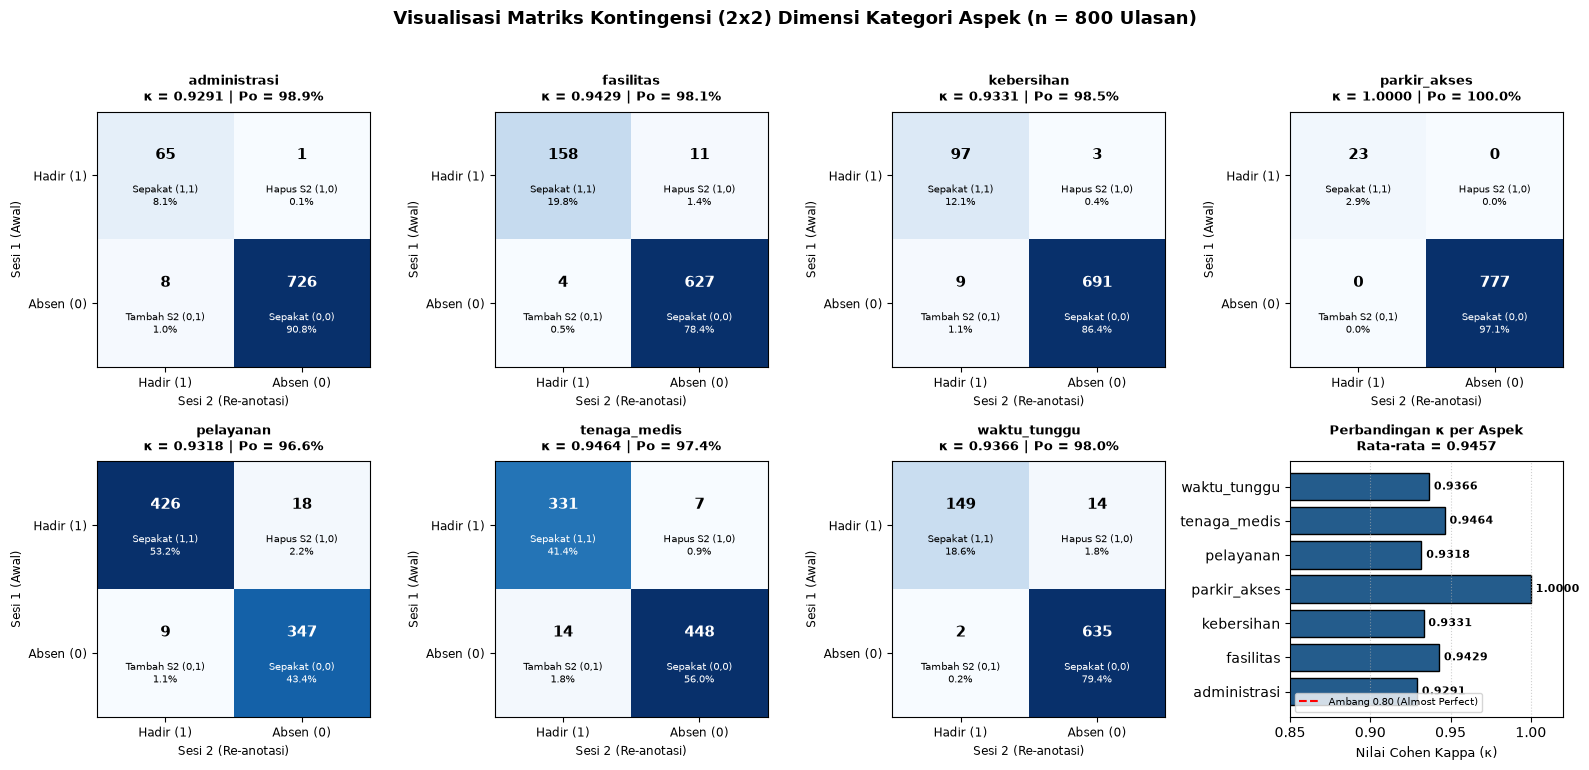

<string>:70: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


In [7]:
import matplotlib.pyplot as plt
import numpy as np

# Konfigurasi font dan estetika visual
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial', 'Helvetica']

def render_cm_subplot(ax, n11, n10, n01, n00, title, kappa_val, po_val, cmap='Blues'):
    """Fungsi pembantu untuk merender 1 subplot matriks kontingensi 2x2."""
    matrix = np.array([[n11, n10], [n01, n00]])
    im = ax.imshow(matrix, cmap=cmap, interpolation='nearest', aspect='auto')
    
    max_val = max(n11, n00, n10, n01)
    cell_desc = [
        [(f"{n11}", f"Sepakat (1,1)\n{n11/8:.1f}%"), (f"{n10}", f"Hapus S2 (1,0)\n{n10/8:.1f}%")],
        [(f"{n01}", f"Tambah S2 (0,1)\n{n01/8:.1f}%"), (f"{n00}", f"Sepakat (0,0)\n{n00/8:.1f}%")]
    ]
    
    for i in range(2):
        for j in range(2):
            val = matrix[i, j]
            num_str, sub_str = cell_desc[i][j]
            color = 'white' if val > (max_val * 0.40) else 'black'
            ax.text(j, i - 0.16, num_str, ha='center', va='center', fontsize=11, fontweight='bold', color=color)
            ax.text(j, i + 0.16, sub_str, ha='center', va='center', fontsize=7.5, color=color)
            
    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])
    ax.set_xticklabels(['Hadir (1)', 'Absen (0)'], fontsize=8.5)
    ax.set_yticklabels(['Hadir (1)', 'Absen (0)'], fontsize=8.5)
    ax.set_xlabel('Sesi 2 (Re-anotasi)', fontsize=8.5)
    ax.set_ylabel('Sesi 1 (Awal)', fontsize=8.5)
    ax.set_title(f"{title}\nκ = {kappa_val:.4f} | Po = {po_val*100:.1f}%", fontsize=9.5, fontweight='bold', pad=8)

# Visualisasi Dimensi 1: 7 Kategori Aspek
fig, axes = plt.subplots(2, 4, figsize=(16, 7.5))
axes = axes.flatten()

dim_name, keys, keyfn = DIMENSIONS[0]
index_map = {k: i for i, k in enumerate(keys)}
S1 = masks_of(data_sesi_1, sample_ids, keyfn, index_map)
S2 = masks_of(data_sesi_2, sample_ids, keyfn, index_map)
n = len(sample_ids)

aspect_kappas = []
for idx, cat_name in enumerate(keys):
    bit = 1 << idx
    n11 = sum(1 for a, b in zip(S1, S2) if (a & bit) and (b & bit))
    n10 = sum(1 for a, b in zip(S1, S2) if (a & bit) and not (b & bit))
    n01 = sum(1 for a, b in zip(S1, S2) if not (a & bit) and (b & bit))
    n00 = sum(1 for a, b in zip(S1, S2) if not (a & bit) and not (b & bit))
    res = cohen_kappa_2x2(n11, n10, n01, n00, n)
    aspect_kappas.append(res['kappa'])
    render_cm_subplot(axes[idx], n11, n10, n01, n00, cat_name, res['kappa'], res['po'], cmap='Blues')

# Subplot ke-8: Grafik Batang Perbandingan Nilai Kappa per Aspek
ax_bar = axes[7]
bars = ax_bar.barh(keys, aspect_kappas, color='#245c8c', edgecolor='black')
ax_bar.axvline(0.80, color='red', linestyle='--', linewidth=1.5, label='Ambang 0.80 (Almost Perfect)')
ax_bar.set_xlim(0.85, 1.02)
ax_bar.set_xlabel('Nilai Cohen Kappa (κ)', fontsize=9)
ax_bar.set_title(f"Perbandingan κ per Aspek\nRata-rata = {sum(aspect_kappas)/len(aspect_kappas):.4f}", fontsize=9.5, fontweight='bold', pad=8)
for bar, val in zip(bars, aspect_kappas):
    ax_bar.text(val + 0.003, bar.get_y() + bar.get_height() / 2, f"{val:.4f}", va='center', fontsize=8, fontweight='bold')
ax_bar.legend(loc='lower left', fontsize=7.5)
ax_bar.grid(axis='x', linestyle=':', alpha=0.6)

plt.suptitle("Visualisasi Matriks Kontingensi (2x2) Dimensi Kategori Aspek (n = 800 Ulasan)", fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


---
## 6.2 Visualisasi Matriks Kontingensi (Confusion Matrix $2 \times 2$) Kelas Sentimen

Visualisasi ini menampilkan matriks biner untuk ketiga kelas polaritas:
1. **Negatif:** Menunjukkan konsistensi sangat tinggi ($\kappa = 0{,}9643$), hanya $11$ ulasan dihapus dan $3$ ulasan ditambahkan.
2. **Netral:** Memiliki nilai $\kappa = 0{,}7935$ karena anotator cenderung menambahkan sentimen netral pada sesi kedua ($n_{01} = 32$ kasus ulasan samar dibaca lebih objektif).
3. **Positif:** Menunjukkan konsistensi hampir sempurna ($\kappa = 0{,}9713$) dengan $475$ ulasan sepakat hadir ($59{,}4\%$).


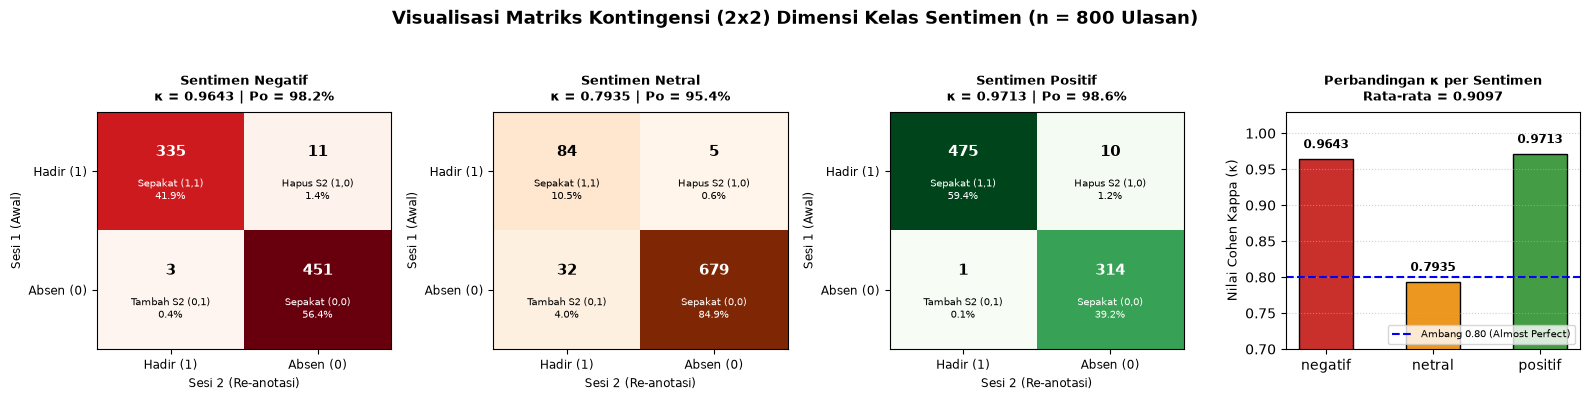

<string>:37: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


In [8]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))

dim_name, keys, keyfn = DIMENSIONS[1]
index_map = {k: i for i, k in enumerate(keys)}
S1 = masks_of(data_sesi_1, sample_ids, keyfn, index_map)
S2 = masks_of(data_sesi_2, sample_ids, keyfn, index_map)
n = len(sample_ids)

sent_kappas = []
cmaps = ['Reds', 'Oranges', 'Greens']

for idx, cat_name in enumerate(keys):
    bit = 1 << idx
    n11 = sum(1 for a, b in zip(S1, S2) if (a & bit) and (b & bit))
    n10 = sum(1 for a, b in zip(S1, S2) if (a & bit) and not (b & bit))
    n01 = sum(1 for a, b in zip(S1, S2) if not (a & bit) and (b & bit))
    n00 = sum(1 for a, b in zip(S1, S2) if not (a & bit) and not (b & bit))
    res = cohen_kappa_2x2(n11, n10, n01, n00, n)
    sent_kappas.append(res['kappa'])
    render_cm_subplot(axes[idx], n11, n10, n01, n00, f"Sentimen {cat_name.title()}", res['kappa'], res['po'], cmap=cmaps[idx])

# Subplot ke-4: Grafik Batang Perbandingan Nilai Kappa Sentimen
ax_bar = axes[3]
colors = ['#c9302c', '#ec971f', '#449d44']
bars = ax_bar.bar(keys, sent_kappas, color=colors, edgecolor='black', width=0.5)
ax_bar.axhline(0.80, color='blue', linestyle='--', linewidth=1.5, label='Ambang 0.80 (Almost Perfect)')
ax_bar.set_ylim(0.70, 1.03)
ax_bar.set_ylabel('Nilai Cohen Kappa (κ)', fontsize=9)
ax_bar.set_title(f"Perbandingan κ per Sentimen\nRata-rata = {sum(sent_kappas)/len(sent_kappas):.4f}", fontsize=9.5, fontweight='bold', pad=8)
for bar, val in zip(bars, sent_kappas):
    ax_bar.text(bar.get_x() + bar.get_width() / 2, val + 0.015, f"{val:.4f}", ha='center', fontsize=8.5, fontweight='bold')
ax_bar.legend(loc='lower right', fontsize=7.5)
ax_bar.grid(axis='y', linestyle=':', alpha=0.6)

plt.suptitle("Visualisasi Matriks Kontingensi (2x2) Dimensi Kelas Sentimen (n = 800 Ulasan)", fontsize=13, fontweight='bold', y=1.04)
plt.tight_layout()
plt.show()


---
## 6.3 Visualisasi Matriks Kontingensi Dimensi Pasangan Aspek–Sentimen (21 Kategori)

Dimensi Pasangan Aspek–Sentimen menggabungkan deteksi aspek dan penentuan sentimen secara simultan ($7 \times 3 = 21$ kombinasi).
Di bawah ini disajikan dua bentuk visualisasi:
1. **Peta Heatmap Ringkasan Matrix $7 \times 3$:** Memperlihatkan nilai Cohen's Kappa ($\kappa$) di setiap perpotongan aspek dan sentimen beserta jumlah ulasan sepakat hadir ($n_{11}$).
2. **Detail 21 Matriks Kontingensi $2 \times 2$ Grid $7 \times 3$:** Menampilkan struktur matriks kontingensi lengkap untuk masing-masing ke-21 pasangan kategori.


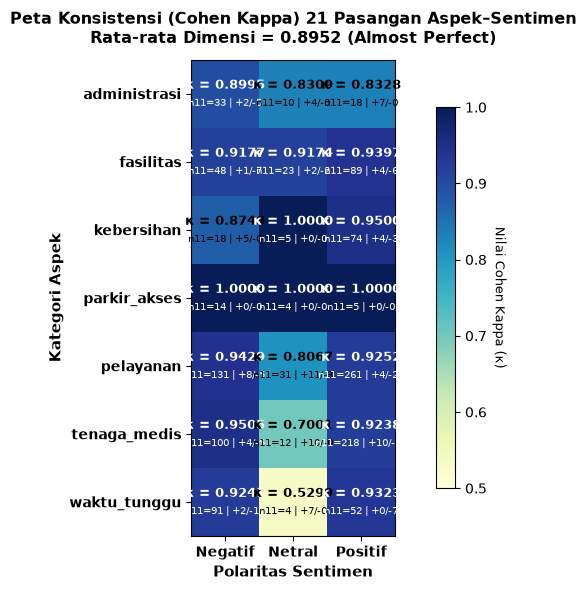

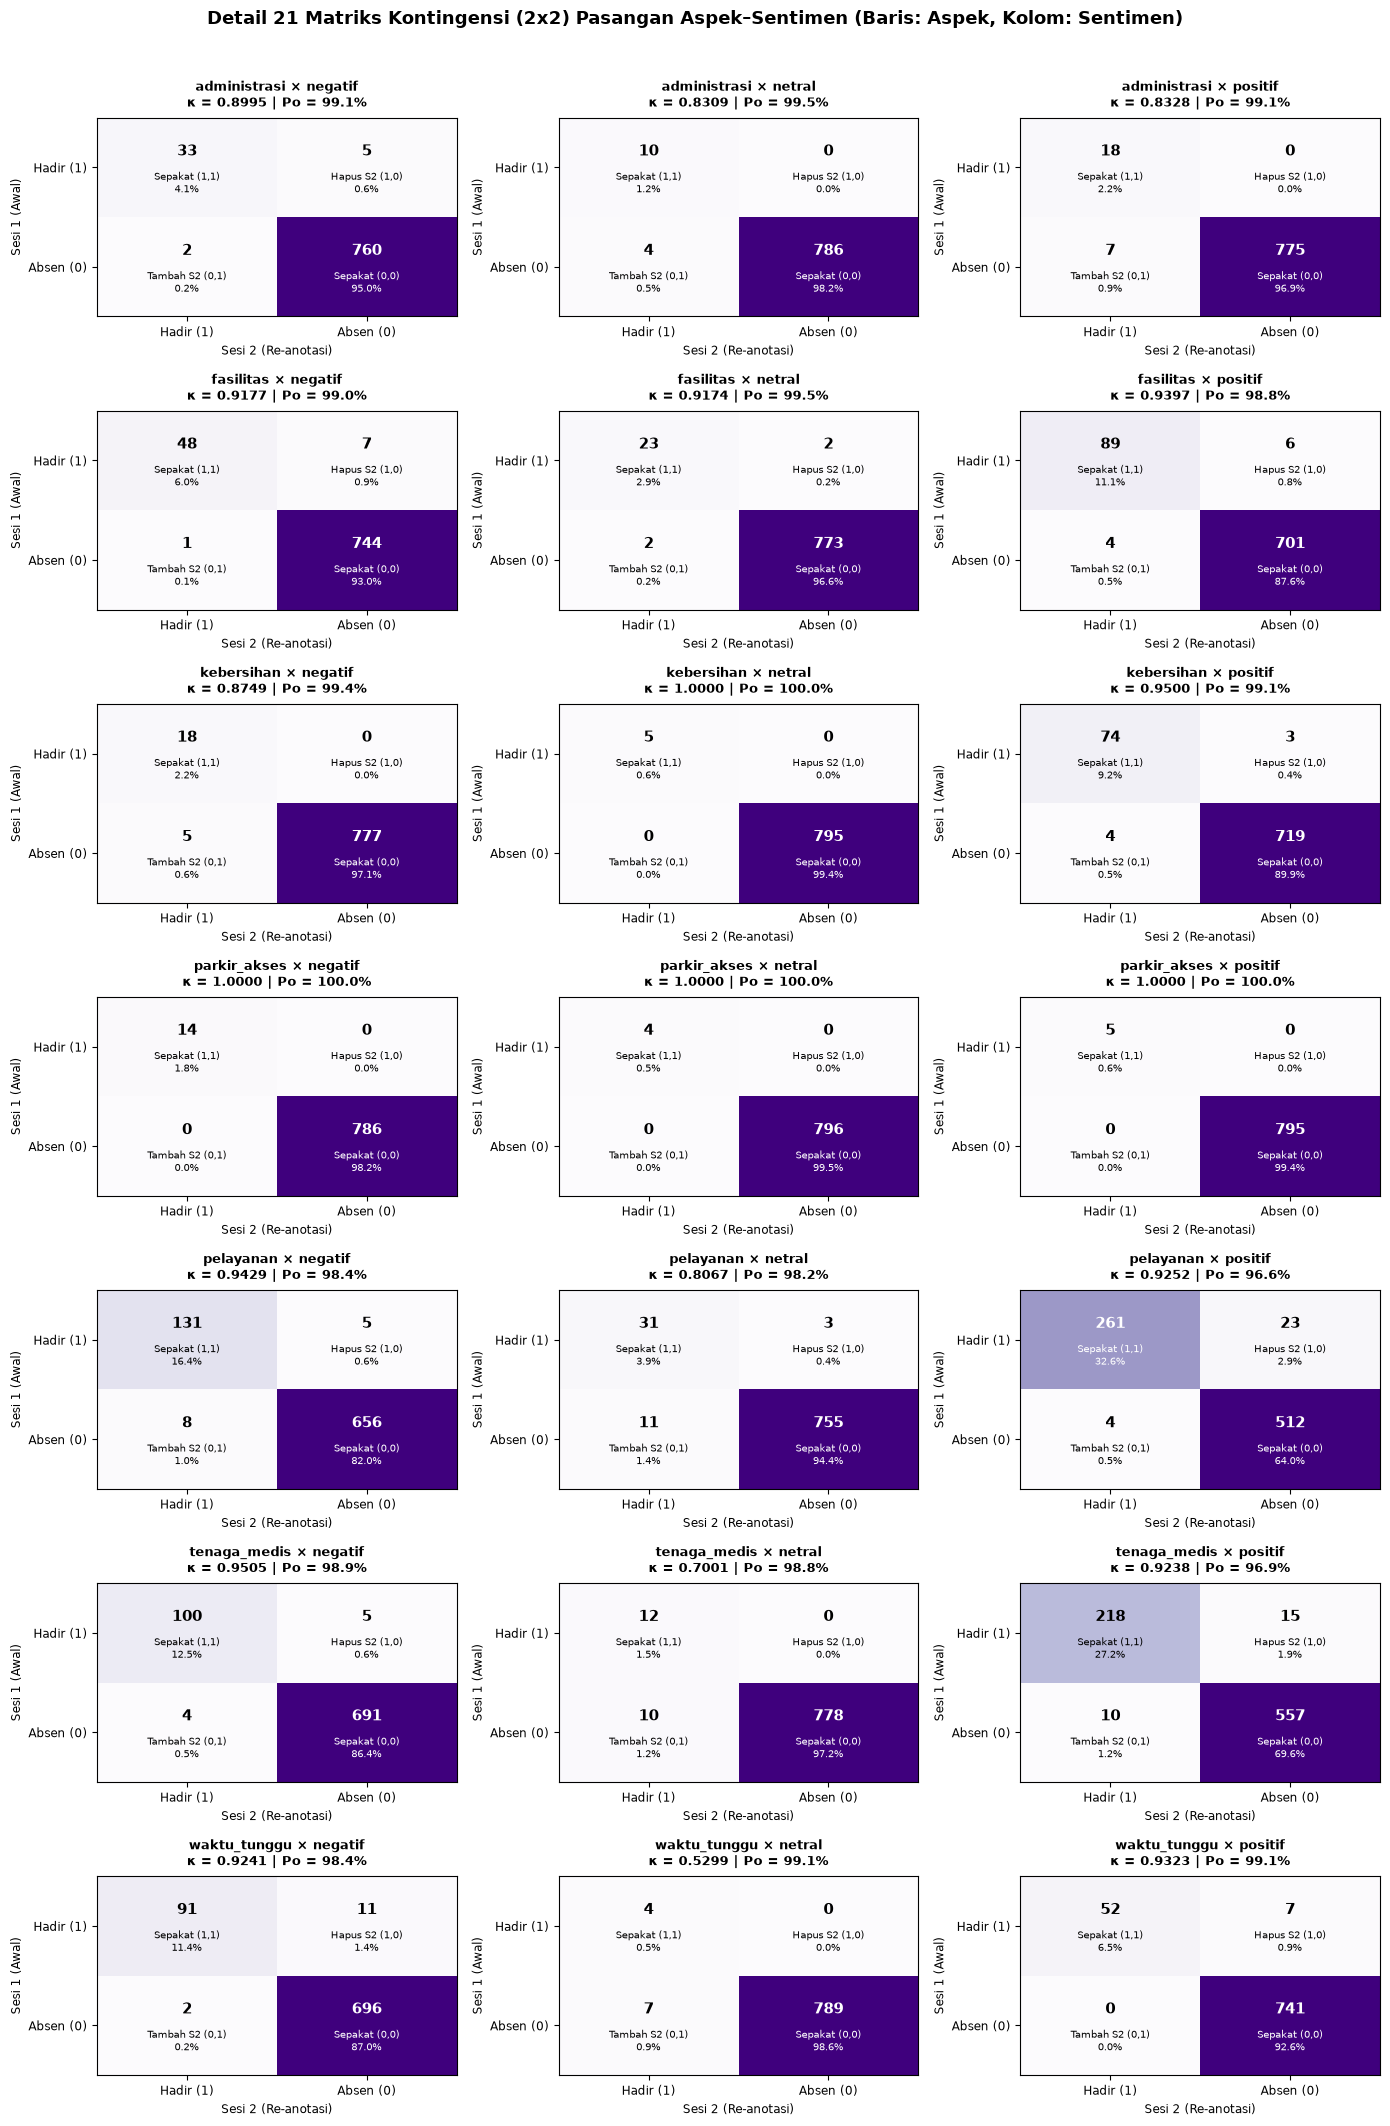

<string>:56: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
<string>:70: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


In [9]:
# Bagian 1: Heatmap Ringkasan 7 Aspek x 3 Sentimen
dim_name, keys, keyfn = DIMENSIONS[2]
index_map = {k: i for i, k in enumerate(keys)}
S1 = masks_of(data_sesi_1, sample_ids, keyfn, index_map)
S2 = masks_of(data_sesi_2, sample_ids, keyfn, index_map)
n = len(sample_ids)

kappa_matrix = np.zeros((len(ASPECTS), len(SENTS)))
n11_matrix = np.zeros((len(ASPECTS), len(SENTS)), dtype=int)
n10_matrix = np.zeros((len(ASPECTS), len(SENTS)), dtype=int)
n01_matrix = np.zeros((len(ASPECTS), len(SENTS)), dtype=int)

pair_details = {}
for i, asp in enumerate(ASPECTS):
    for j, snt in enumerate(SENTS):
        pair_code = f"{asp}__{snt}"
        idx = index_map[pair_code]
        bit = 1 << idx
        n11 = sum(1 for a, b in zip(S1, S2) if (a & bit) and (b & bit))
        n10 = sum(1 for a, b in zip(S1, S2) if (a & bit) and not (b & bit))
        n01 = sum(1 for a, b in zip(S1, S2) if not (a & bit) and (b & bit))
        n00 = sum(1 for a, b in zip(S1, S2) if not (a & bit) and not (b & bit))
        res = cohen_kappa_2x2(n11, n10, n01, n00, n)
        
        kappa_matrix[i, j] = res['kappa']
        n11_matrix[i, j] = n11
        n10_matrix[i, j] = n10
        n01_matrix[i, j] = n01
        pair_details[pair_code] = (n11, n10, n01, n00, res['kappa'], res['po'])

# Plot Heatmap Overview 7x3
fig, ax = plt.subplots(figsize=(8.5, 6))
im = ax.imshow(kappa_matrix, cmap='YlGnBu', vmin=0.50, vmax=1.0)
cbar = ax.figure.colorbar(im, ax=ax, shrink=0.8)
cbar.ax.set_ylabel('Nilai Cohen Kappa (κ)', rotation=-90, va='bottom', fontsize=9.5)

ax.set_xticks(range(len(SENTS)))
ax.set_yticks(range(len(ASPECTS)))
ax.set_xticklabels([s.title() for s in SENTS], fontsize=10, fontweight='bold')
ax.set_yticklabels(ASPECTS, fontsize=10, fontweight='bold')
ax.set_xlabel('Polaritas Sentimen', fontsize=10.5, fontweight='bold')
ax.set_ylabel('Kategori Aspek', fontsize=10.5, fontweight='bold')
ax.set_title('Peta Konsistensi (Cohen Kappa) 21 Pasangan Aspek–Sentimen\nRata-rata Dimensi = 0.8952 (Almost Perfect)', fontsize=11.5, fontweight='bold', pad=12)

for i in range(len(ASPECTS)):
    for j in range(len(SENTS)):
        k_val = kappa_matrix[i, j]
        n11_val = n11_matrix[i, j]
        n10_val = n10_matrix[i, j]
        n01_val = n01_matrix[i, j]
        color = 'white' if k_val > 0.88 else 'black'
        ax.text(j, i - 0.12, f"κ = {k_val:.4f}", ha='center', va='center', fontsize=9, fontweight='bold', color=color)
        ax.text(j, i + 0.14, f"n11={n11_val} | +{n01_val}/-{n10_val}", ha='center', va='center', fontsize=7.5, color=color)

plt.tight_layout()
plt.show()

# Bagian 2: Detail 21 Matriks Kontingensi 2x2 disusun dalam Grid 7x3
fig, axes = plt.subplots(7, 3, figsize=(14, 21))

for i, asp in enumerate(ASPECTS):
    for j, snt in enumerate(SENTS):
        ax = axes[i, j]
        pair_code = f"{asp}__{snt}"
        n11, n10, n01, n00, k_val, po_val = pair_details[pair_code]
        render_cm_subplot(ax, n11, n10, n01, n00, f"{asp} × {snt}", k_val, po_val, cmap='Purples')

plt.suptitle("Detail 21 Matriks Kontingensi (2x2) Pasangan Aspek–Sentimen (Baris: Aspek, Kolom: Sentimen)", fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()


---
## 7. Metrik 4: Krippendorff's Alpha ($\alpha$) dengan Jarak Jaccard

### 📐 Rumus Matematis
Krippendorff's Alpha mengoreksi ketidaksepakatan teramati (*Observed Disagreement*, $D_o$) terhadap ketidaksepakatan harapan kebetulan (*Expected Disagreement*, $D_e$):
$$\alpha^{(d)} = 1 - \frac{D_o^{(d)}}{D_e^{(d)}}$$

1. **Jarak Jaccard antar Himpunan:**
   $$\delta(A, B) = 1 - \frac{|A \cap B|}{|A \cup B|}, \qquad \delta(\varnothing, \varnothing) = 0$$

2. **Ketidaksepakatan Teramati ($D_o$):**
   Diukur dari pasangan ulasan yang sama antara Sesi 1 dan Sesi 2:
   $$D_o^{(d)} = \frac{1}{n}\sum_{i=1}^{n} \delta\!\left(A_i^{(d)}, B_i^{(d)}\right) = 1 - \bar{J}^{(d)}$$

3. **Ketidaksepakatan Harapan ($D_e$):**
   Diukur dari **seluruh kemungkinan pasangan** dalam gabungan data kedua sesi (pool berukuran $2n = 1.600$ himpunan).
   Total kombinasi pasangan acak:
   $$\binom{2n}{2} = \frac{2n(2n - 1)}{2} = \frac{1600 \times 1599}{2} = 1.279.200 \text{ pasangan}$$
   $$D_e^{(d)} = \frac{1}{\binom{2n}{2}}\sum_{x < y} \delta(x, y)$$

4. **Estimasi Ketidakpastian (Bootstrap):**
   Dilakukan *resampling with replacement* sebanyak $B = 60$ iterasi pada tingkat ulasan untuk mengestimasi *Standard Error* (SE) dan $95\%$ *Confidence Interval* (CI $95\%$).


In [10]:
def fast_pairs_dist(pool):
    """
    Menghitung total jarak Jaccard seluruh C(N, 2) pasangan secara eksak dan instan
    menggunakan agregasi frekuensi Counter(unique_bitmasks).
    Kompleksitas: O(K^2) dengan K <= 200 unik, bukan O(N^2) pasangan.
    """
    counts = Counter(pool)
    unique_items = list(counts.keys())
    total_dist = 0.0
    for i in range(len(unique_items)):
        u = unique_items[i]
        c_u = counts[u]
        for j in range(i + 1, len(unique_items)):
            v = unique_items[j]
            c_v = counts[v]
            total_dist += (c_u * c_v) * jdist(u, v)
    return total_dist

def bootstrap_alpha(S1, S2, seed=42, n_iter=60):
    """Estimasi Standard Error dan CI 95% untuk Krippendorff's Alpha via bootstrap."""
    rng = random.Random(seed)
    n = len(S1)
    alpha_samples = []
    for _ in range(n_iter):
        indices = [rng.randrange(n) for _ in range(n)]
        boot_s1 = [S1[i] for i in indices]
        boot_s2 = [S2[i] for i in indices]
        
        do_b = sum(jdist(a, b) for a, b in zip(boot_s1, boot_s2)) / n
        pool_b = boot_s1 + boot_s2
        N_b = len(pool_b)
        de_b = fast_pairs_dist(pool_b) / (N_b * (N_b - 1) / 2)
        alpha_samples.append(1.0 - (do_b / de_b))
        
    alpha_samples.sort()
    mean_boot = sum(alpha_samples) / n_iter
    se = (sum((x - mean_boot) ** 2 for x in alpha_samples) / (n_iter - 1)) ** 0.5
    idx_lower = int((n_iter - 1) * 0.025)
    idx_upper = n_iter - 1 - idx_lower
    ci_95 = (alpha_samples[idx_lower], alpha_samples[idx_upper])
    return se, ci_95

hasil_alpha = {}

print("=" * 70)
print("PERHITUNGAN METRIK 4: KRIPPENDORFF'S ALPHA DENGAN JARAK JACCARD")
print("=" * 70)

for dim_name, keys, keyfn in DIMENSIONS:
    index_map = {k: i for i, k in enumerate(keys)}
    S1 = masks_of(data_sesi_1, sample_ids, keyfn, index_map)
    S2 = masks_of(data_sesi_2, sample_ids, keyfn, index_map)
    n = len(sample_ids)
    
    # 1. Observed Disagreement (D_o)
    Do = sum(jdist(a, b) for a, b in zip(S1, S2)) / n
    
    # 2. Expected Disagreement (D_e)
    pool = S1 + S2
    N_pool = len(pool)
    total_pairs = N_pool * (N_pool - 1) // 2
    sum_dist = fast_pairs_dist(pool)
    De = sum_dist / total_pairs
    
    # 3. Alpha
    ratio_Do_De = Do / De
    alpha = 1.0 - ratio_Do_De
    
    # 4. Bootstrap
    se, ci = bootstrap_alpha(S1, S2, seed=42, n_iter=60)
    hasil_alpha[dim_name] = alpha
    
    print(f"### Dimensi: {dim_name}")
    print(f"  Variabel n (Ulasan)                   : {n}")
    print(f"  Variabel Ukuran Pool Gabungan (2n)    : {N_pool}")
    print(f"  Variabel Total Pasangan C(2n, 2)      : {total_pairs:,} pasangan")
    print(f"  Variabel Total Jarak Gabungan (sum_d) : {sum_dist:.4f}")
    print(f"  Variabel D_o (Observed Disagreement)  : {Do:.6f} (= 1 - Mean Jaccard)")
    print(f"  Variabel D_e (Expected Disagreement)  : {De:.6f}")
    print(f"  Variabel Rasio D_o / D_e              : {ratio_Do_De:.6f}")
    print(f"  Rumus Alpha = 1 - ({Do:.6f} / {De:.6f})")
    print(f"  Nilai Krippendorff's Alpha            : {alpha:.4f}")
    print(f"  Standard Error (Bootstrap, B=60)      : {se:.4f}")
    print(f"  Confidence Interval 95%               : [{ci[0]:.4f} ; {ci[1]:.4f}]")
    print("-" * 70)


PERHITUNGAN METRIK 4: KRIPPENDORFF'S ALPHA DENGAN JARAK JACCARD
### Dimensi: Kategori Aspek
  Variabel n (Ulasan)                   : 800
  Variabel Ukuran Pool Gabungan (2n)    : 1600
  Variabel Total Pasangan C(2n, 2)      : 1,279,200 pasangan
  Variabel Total Jarak Gabungan (sum_d) : 926695.6286
  Variabel D_o (Observed Disagreement)  : 0.052083 (= 1 - Mean Jaccard)
  Variabel D_e (Expected Disagreement)  : 0.724434
  Variabel Rasio D_o / D_e              : 0.071895
  Rumus Alpha = 1 - (0.052083 / 0.724434)
  Nilai Krippendorff's Alpha            : 0.9281
  Standard Error (Bootstrap, B=60)      : 0.0095
  Confidence Interval 95%               : [0.9111 ; 0.9500]
----------------------------------------------------------------------
### Dimensi: Kelas Sentimen
  Variabel n (Ulasan)                   : 800
  Variabel Ukuran Pool Gabungan (2n)    : 1600
  Variabel Total Pasangan C(2n, 2)      : 1,279,200 pasangan
  Variabel Total Jarak Gabungan (sum_d) : 723217.3333
  Variabel D_o (Obs

---
## 8. Interpretasi Hasil & Pembahasan Akademik

### 📋 Pedoman Interpretasi Kesepakatan (Landis & Koch, 1977)
Untuk metrik *chance-corrected* (Cohen's Kappa dan Krippendorff's Alpha), interpretasi tingkat reliabilitas mengikuti kriteria standar:

| Rentang Koefisien ($\kappa$ atau $\alpha$) | Tingkat Kesepakatan (*Strength of Agreement*) |
|---|---|
| $< 0{,}00$ | *Poor agreement* (lebih buruk dari kebetulan) |
| $0{,}00 - 0{,}20$ | *Slight agreement* |
| $0{,}21 - 0{,}40$ | *Fair agreement* |
| $0{,}41 - 0{,}60$ | *Moderate agreement* |
| $0{,}61 - 0{,}80$ | *Substantial agreement* |
| $\mathbf{0{,}81 - 1{,}00}$ | $\mathbf{Almost\ perfect\ agreement}$ |

---

### 🎓 Poin Tanya Jawab Sidang Skripsi (*Defense Preparation*):

1. **Apakah hasil ini membuktikan kesepakatan antar-anotator (*Inter-Annotator Agreement*)?**
   > **Jawaban Tegas:** Tidak. Karena anotasi dilakukan oleh satu anotator utama, klaim metodologis yang tepat adalah **Reliabilitas Internal / Konsistensi Intra-Anotator (*Intra-Annotator Reliability*)**. Validitas eksternal dan kesesuaian konsep didukung oleh pedoman anotasi berbasis kerangka SERVQUAL dan uji petik oleh peninjau ahli (*expert spot-checking*).

2. **Mengapa nilai pada dimensi Pasangan Aspek–Sentimen ($85{,}9\%$) lebih rendah dari Kategori Aspek ($91{,}2\%$) dan Sentimen ($94{,}8\%$)?**
   > **Jawaban Metodologis:** Karena dimensi pasangan menuntut ketepatan simultan (*joint matching*) antara aspek dan polaritas secara bersamaan ($7 \times 3 = 21$ kombinasi). Kesalahan pada salah satu komponen langsung menyebabkan kegagalan pencocokan pasangan. Kendati demikian, koefisien Kappa ($0{,}8952$) dan Alpha ($0{,}8947$) tetap jauh melampaui batas ambang $0{,}80$.

3. **Mengapa Cohen's Kappa untuk kelas sentimen `netral` lebih rendah ($0{,}7935$)?**
   > **Jawaban Analitis:** Sentimen netral memiliki prevalensi paling rendah dan berada di zona batas abu-abu (*boundary cases*). Pada sesi kedua, anotator cenderung membaca sebagian ulasan bernada samar secara lebih objektif/netral ($n_{01} = 32$). Namun, rata-rata dimensi sentimen secara menyeluruh tetap sangat tinggi ($0{,}9097$).


In [11]:
print("=" * 80)
print("REKAPITULASI HASIL PERHITUNGAN KONSISTENSI ANOTASI (INTRA-ANNOTATOR)")
print("=" * 80)
print(f"{'Dimensi Evaluasi':<25} | {'Metrik':<24} | {'Nilai Komputasi':<16} | {'Kategori (Landis & Koch)':<24}")
print("-" * 80)

for dim_name in ["Kategori Aspek", "Kelas Sentimen", "Pasangan Aspek-Sentimen"]:
    nb_po = hasil_po[dim_name] * 100.0
    print(f"{dim_name:<25} | {'P_o (Set-Label)':<24} | {nb_po:>6.2f}%          | {'Kesepakatan Penuh':<24}")
    
    nb_jc = hasil_jaccard[dim_name] * 100.0
    print(f"{'':<25} | {'Mean Jaccard':<24} | {nb_jc:>6.2f}%          | {'Kesamaan Parsial':<24}")
    
    nb_kp = hasil_kappa[dim_name]
    print(f"{'':<25} | {'Cohen Kappa (rata-rata)':<24} | {nb_kp:>6.4f}           | {'Almost Perfect':<24}")
    
    nb_al = hasil_alpha[dim_name]
    print(f"{'':<25} | {'Krippendorff Alpha':<24} | {nb_al:>6.4f}           | {'Almost Perfect':<24}")
    print("-" * 80)

print("""
KESIMPULAN METODOLOGIS:
1. Seluruh nilai koefisien chance-corrected (Cohen's Kappa dan Krippendorff's Alpha) 
   berada pada rentang 0.89 s.d. 0.95 (> 0.80).
2. Berdasarkan pedoman Landis & Koch (1977), data ground truth penelitian berada pada 
   kategori 'ALMOST PERFECT AGREEMENT'.
3. Data terbukti memiliki reliabilitas internal dan konsistensi keputusan anotasi 
   yang sangat tinggi dan valid sebagai acuan evaluasi model generatif GABSA.
""")


REKAPITULASI HASIL PERHITUNGAN KONSISTENSI ANOTASI (INTRA-ANNOTATOR)
Dimensi Evaluasi          | Metrik                   | Nilai Komputasi  | Kategori (Landis & Koch)
--------------------------------------------------------------------------------
Kategori Aspek            | P_o (Set-Label)          |  91.25%          | Kesepakatan Penuh       
                          | Mean Jaccard             |  94.79%          | Kesamaan Parsial        
                          | Cohen Kappa (rata-rata)  | 0.9457           | Almost Perfect          
                          | Krippendorff Alpha       | 0.9281           | Almost Perfect          
--------------------------------------------------------------------------------
Kelas Sentimen            | P_o (Set-Label)          |  94.75%          | Kesepakatan Penuh       
                          | Mean Jaccard             |  96.17%          | Kesamaan Parsial        
                          | Cohen Kappa (rata-rata)  | 0.9097           | Al